# Project 1: BRFSS heart attack risk (baseline)

Goal: predict MICHD (labels `-1` / `+1`) from BRFSS survey features with a reproducible NumPy pipeline.

Constraints: no pandas or sklearn. Sample ids are used only for the submission file.

**Steps in this notebook**
1. Load data and check class imbalance
2. Diagnose missing values and feature types
3. Choose a missing rate cut and justify drops
4. Check whether missingness and means differ by label
5. Stratified preprocess (fit on train fold only)
6. Validate logistic regression
7. Refit on all labelled data and write the submission


## Setup

Reload `src.eda` and `src.preprocessing` so notebook edits pick up without restarting the kernel.


In [49]:
# Prefer eda.f and prep.f. A bare `from src.eda import f` stays stale under autoreload.
%load_ext autoreload
%autoreload 2

import importlib
import numpy as np
from helpers import load_csv_data, create_csv_submission
from implementations import logistic_regression
import src.eda as eda
import src.preprocessing as prep

importlib.reload(eda)
importlib.reload(prep)

np.random.seed(42)
data = "data/dataset"


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load data

`load_csv_data` returns train/test matrices, labels, and ids. Positive class is MICHD (`y = 1`).


In [50]:
x_train, x_test, y_train, ids_train, ids_test = load_csv_data(data)
proportions = eda.class_proportions(y_train)
print(f"train X {x_train.shape}, test X {x_test.shape}, train y {y_train.shape}")
print(f"class proportions: {proportions}")


train X (328135, 321), test X (109379, 321), train y (328135,)
class proportions: {-1: 0.911697929205967, 1: 0.08830207079403295}


Train has 328135 rows × 321 features; test has 109379 rows with the same width. The positive MICHD rate is only 8.8%, so a majority classifier would already score about 91% accuracy. Balanced accuracy is the metric that matters for model choice.


## 1. Data diagnostics

Missing entries are IEEE `NaN` (empty CSV cells). Before transforming anything we:
- measure overall and per column missingness (train vs test)
- list constant columns (zero information)
- classify columns as constant / binary / ordinal / continuous
- plot class counts and per column missing rates


NaNs train: 47175779/105331335 (44.8%), cols with NaN: 239/321
NaNs test:  15724379/35110659 (44.8%), cols with NaN: 232/321
constant cols: 6/321, indices: [ 9 11 12 18 19 22]
kinds: {'constant': 6, 'binary': 14, 'ordinal': 221, 'continuous': 80, 'quasi_constant': 6}
cols with >50% missing: 147


<Axes: title={'center': 'missing rate by column'}>

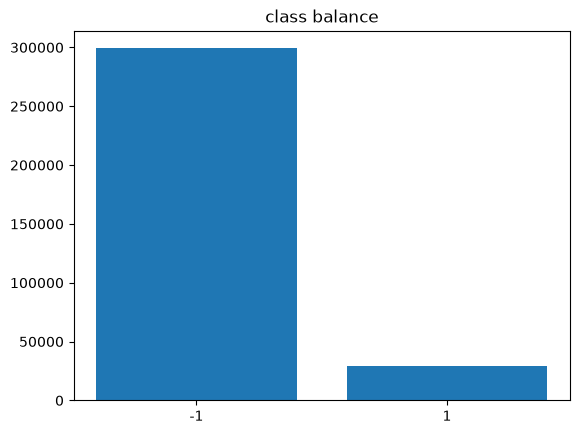

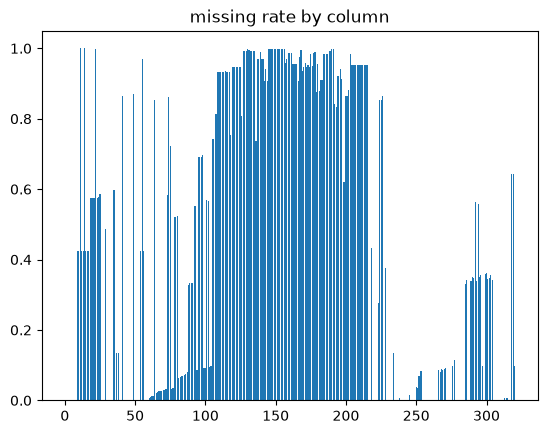

In [51]:
n, d = x_train.shape
miss = eda.missing_count(x_train)
rates = eda.missing_rate(x_train)
drop = eda.constant_mask(x_train)
kinds = eda.classify_columns(x_train)

print(
    f"NaNs train: {miss.sum()}/{n * d} ({100 * miss.sum() / (n * d):.1f}%), "
    f"cols with NaN: {(miss > 0).sum()}/{d}"
)
miss_te = eda.missing_count(x_test)
n_te = x_test.shape[0]
print(
    f"NaNs test:  {miss_te.sum()}/{n_te * d} ({100 * miss_te.sum() / (n_te * d):.1f}%), "
    f"cols with NaN: {(miss_te > 0).sum()}/{d}"
)
print(f"constant cols: {int(drop.sum())}/{d}, indices: {np.flatnonzero(drop)}")
print("kinds:", {k: int(v.sum()) for k, v in kinds.items()})
print("cols with >50% missing:", int((rates > 0.5).sum()))

eda.plot_class_balance(y_train, title="MICHD class balance (train)")
eda.plot_missing_rates(rates, title="Missing rate by column (train)")


About 44.8% of train and test entries are NaN, with a similar column footprint (239 vs 232 columns touched). There is no obvious train vs test missingness shift. Six columns are constant (`[9, 11, 12, 18, 19, 22]`). Most features are ordinal (221), with 80 continuous and 14 binary. 147 columns exceed 50% missing and dominate the sparse bar chart.


## 1b. Missing rate threshold

**Choice:** `rate_miss = 0.5`. If more than half the values are missing, median impute invents most of the column and adds little reliable signal.

We do not drop rows: every test id needs a prediction, and a train only row filter would shift the distribution.

The next cell inspects a few high missing columns; the cell after that shows how many features we keep as the threshold moves.


cols with >50% missing: 147 e.g. [11 14 18 19 20 21 22 23 24 25 35 41 49 55 64]


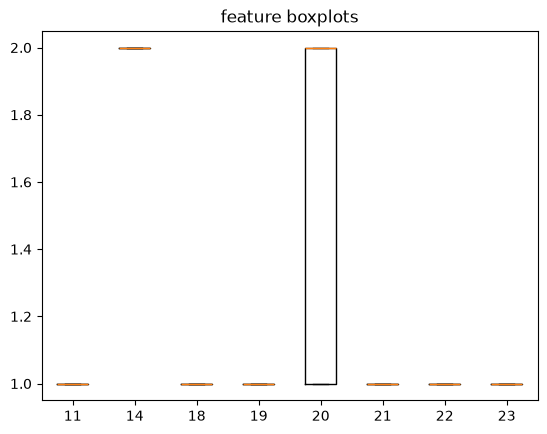

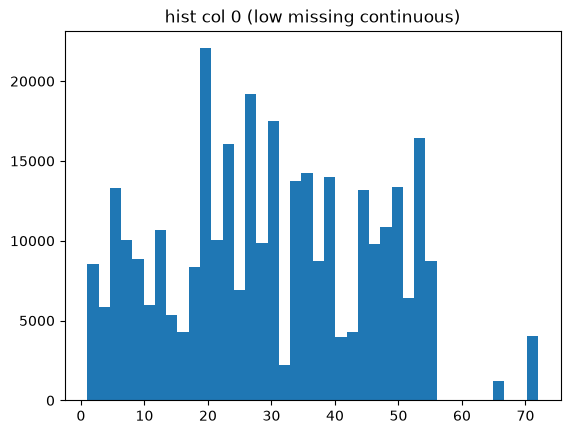

In [52]:
import matplotlib.pyplot as plt

rate_miss = 0.5
hi_miss = np.flatnonzero(rates > rate_miss)
print(f"cols with >{rate_miss*100:g}% missing: {hi_miss.size} e.g. {hi_miss[:15]}")

eda.plot_feature_boxplots(
    x_train, hi_miss[:8], title="High missing columns (observed values only)"
)

cand = np.flatnonzero(kinds["continuous"] & (rates < 0.3) & (~drop))
col = int(cand[0])
plt.figure()
plt.hist(x_train[:, col][np.isfinite(x_train[:, col])], bins=40)
plt.title(f"hist col {col} (low missing continuous)")
plt.show()


The high missing boxplots still show some structure on the observed slice, but those columns are mostly empty, so median impute would invent most values. The low missing continuous histogram is the kind of feature the baseline should keep.


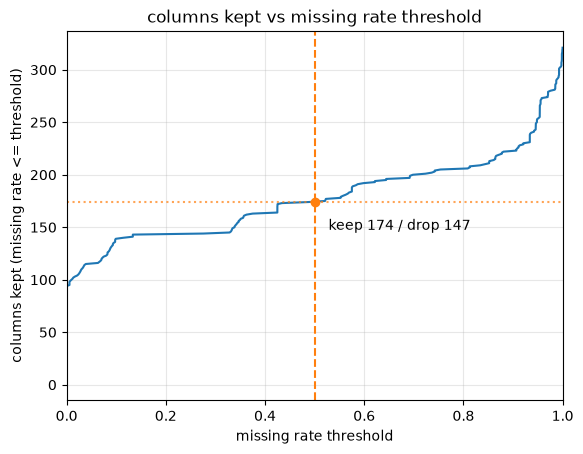

at rate_miss=0.5: 174 kept, 147 dropped


In [53]:
n_keep = int((rates <= rate_miss).sum())
n_drop = int((rates > rate_miss).sum())
sorted_rates = np.sort(rates)

fig, ax = plt.subplots()
ax.plot(sorted_rates, np.arange(1, len(sorted_rates) + 1))
ax.axvline(rate_miss, color="C1", linestyle="--")
ax.axhline(n_keep, color="C1", linestyle=":", alpha=0.7)
ax.scatter([rate_miss], [n_keep], color="C1", zorder=3)
ax.annotate(
    f"keep {n_keep} / drop {n_drop}",
    xy=(rate_miss, n_keep),
    xytext=(10, -20),
    textcoords="offset points",
)
ax.set_xlabel("missing rate threshold")
ax.set_ylabel("columns kept (missing rate <= threshold)")
ax.set_title("columns kept vs missing rate threshold")
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
plt.show()
print(f"at rate_miss={rate_miss}: {n_keep} kept, {n_drop} dropped")


With `rate_miss = 0.5` the curve keeps 174 columns and drops 147. Adding the six constants (four of which already sit above 50% missing) removes 149 columns in total and leaves 172 features for the model. We keep all rows so every test id can be scored.


## 1c. Relation to the MICHD label

Two checks that matter for medical or survey data:

1. **Missingness by class.** Scatter missing rate in class `-1` vs class `1`. Points on `y = x` mean missingness is shared. Points far off the diagonal mean missingness itself may be informative (not a bug: consider a missing indicator later).
2. **Standardized mean gap.** For low missing continuous or ordinal columns, `(mean_1 - mean_-1) / std` ranks which features separate the classes on a comparable scale.


cols with |missing gap| > 5%: 87/321, max gap=0.37
top |standardized mean gap|:
  col  26  +0.861
  col 248  +0.791
  col 246  +0.772
  col  58  +0.730
  col 249  +0.729
drop plan: 149 cols (6 constant, 147 high missing, overlap 4); keep 172


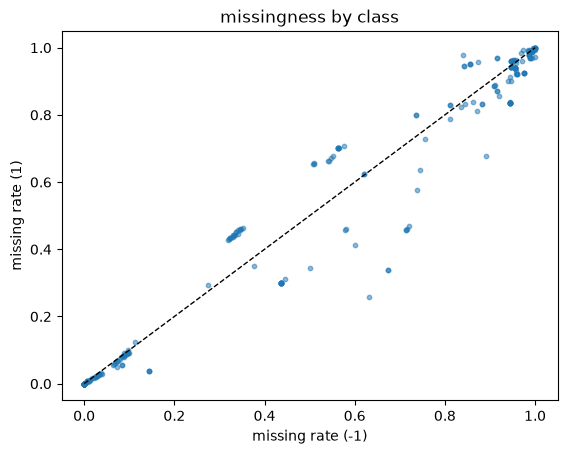

In [54]:
rates_by_y = eda.missing_rate_by_class(x_train, y_train)
r_neg, r_pos = rates_by_y[-1], rates_by_y[1]
eda.plot_missing_rate_by_class(
    r_neg, r_pos, title="Missing rate by MICHD class (on diagonal = shared)"
)
miss_gap = np.abs(r_pos - r_neg)
print(
    f"cols with |missing gap| > 5%: {(miss_gap > 0.05).sum()}/{len(miss_gap)}, "
    f"max gap={miss_gap.max():.2f}"
)

cols, gaps = eda.mean_diff_by_class(
    x_train, y_train, col_mask=kinds["continuous"] | kinds["ordinal"]
)
top = np.argsort(np.abs(gaps))[::-1][:5]
print("top |standardized mean gap|:")
for j, g in zip(cols[top], gaps[top]):
    print(f"  col {int(j):3d}  {g:+.3f}")

const = eda.constant_mask(x_train)
hi = rates > rate_miss
print(
    f"drop plan: {(const | hi).sum()} cols "
    f"({const.sum()} constant, {hi.sum()} high missing, "
    f"overlap {(const & hi).sum()}); keep {(~(const | hi)).sum()}"
)


Missing rates mostly follow the diagonal: 87 columns differ by more than 5% across classes, with a max gap of 0.37, but the bulk of NaNs is shared. Median impute is therefore a fair baseline; the off diagonal columns are candidates for a missing indicator later, not blockers.

The strongest standardized mean gaps on low missing columns are `26, 248, 246, 58, 249` (up to about 0.86 std). They survive the 0.5 missing cut. Drop plan for the report: 149 columns out (6 constant, 147 high missing, overlap 4), 172 kept.


## 2. Preprocessing (fit stats without leakage)

1. Map labels to `{0, 1}` for logistic regression helpers.
2. Stratified 80/20 split (same positive rate in fit and val).
3. On the **fit** rows only: drop constants and columns with missing rate `> 0.5`, median impute, standardize.
4. Apply that frozen state to val and test (never refit on them).
5. Add a bias column of ones for the linear model.


In [ ]:
y01 = (y_train == 1).astype(float)
rng = np.random.default_rng(42)
val_frac = 0.2
max_missing_rate = 0.5

fit_idx, val_idx = prep.stratified_split(y01, val_frac, rng)
state = prep.fit_preprocessor(
    x_train[fit_idx], eps=1e-12, max_missing_rate=max_missing_rate
)
x_fit_clean = prep.transform(x_train[fit_idx], state)
x_val_clean = prep.transform(x_train[val_idx], state)
x_test_clean = prep.transform(x_test, state)

tx_fit = np.c_[np.ones(len(x_fit_clean)), x_fit_clean]
tx_val = np.c_[np.ones(len(x_val_clean)), x_val_clean]
tx_test = np.c_[np.ones(len(x_test_clean)), x_test_clean]

print("dropped cols:", int(state["drop"].sum()))
print("shapes fit/val/test:", tx_fit.shape, tx_val.shape, tx_test.shape)
print("fit/val size:", len(fit_idx), len(val_idx))
print("positive rate fit/val:", y01[fit_idx].mean(), y01[val_idx].mean())


After the fit only transform we have shapes `(262508, 173)`, `(65627, 173)`, `(109379, 173)`: 172 features plus a bias column. Fit and val both keep a positive rate of 0.0883, so stratification worked. Medians and scales were fit on the fit fold only.


## 3. Validation baseline

Train logistic regression on the fit fold. Predictions use score threshold 0 and labels `{-1, +1}`.

**Metrics:** accuracy (optimistic under imbalance), TNR / TPR, and balanced accuracy = average of the two recalls. Also compare predicted vs true positive rate on val.


In [ ]:
max_iters, gamma = 20, 0.05
w, loss = logistic_regression(
    y01[fit_idx], tx_fit, np.zeros(tx_fit.shape[1]), max_iters, gamma
)

scores = tx_val @ w
pred = np.where(scores >= 0, 1, -1)
truth = np.where(y01[val_idx] == 1, 1, -1)
accuracy = float(np.mean(pred == truth))
tnr = float(np.mean(pred[truth == -1] == -1))
tpr = float(np.mean(pred[truth == 1] == 1))
balanced_accuracy = 0.5 * (tnr + tpr)
pred_pos_rate = float(np.mean(pred == 1))

print(f"max_iters={max_iters}, gamma={gamma}")
print(f"validation loss: {loss:.4f}")
print(f"accuracy: {accuracy:.4f}")
print(f"balanced accuracy: {balanced_accuracy:.4f} (TNR={tnr:.4f}, TPR={tpr:.4f})")
print(f"pred positive rate: {pred_pos_rate:.4f} (true {y01[val_idx].mean():.4f})")


With `max_iters=20` and `gamma=0.05`, validation loss is about 0.54. Accuracy is about 0.86 while balanced accuracy is about 0.70 (TNR and TPR both matter under 8.8% positives). Use balanced accuracy to compare later ablations; do not tune on the online test.


## 4. Final fit and submission

After choosing hyperparameters on validation, refit preprocessing and the model on **all** labelled rows, predict on test, and write `Id,Prediction` with values in `{-1, +1}`.


In [ ]:
out_path = "submission_logistic_baseline.csv"

state_full = prep.fit_preprocessor(
    x_train, eps=1e-12, max_missing_rate=max_missing_rate
)
x_train_clean = prep.transform(x_train, state_full)
x_test_clean = prep.transform(x_test, state_full)
tx_train = np.c_[np.ones(x_train_clean.shape[0]), x_train_clean]
tx_test = np.c_[np.ones(x_test_clean.shape[0]), x_test_clean]

w_final, final_loss = logistic_regression(
    y01, tx_train, np.zeros(tx_train.shape[1]), max_iters, gamma
)
y_pred = np.where(tx_test @ w_final >= 0, 1, -1)
create_csv_submission(ids_test, y_pred, out_path)

labels, counts = np.unique(y_pred, return_counts=True)
print(f"saved {out_path}, loss={final_loss:.4f}")
print("prediction counts:", dict(zip(labels.astype(int), counts.astype(int))))


The file `submission_logistic_baseline.csv` has one `{-1,+1}` prediction per test id. On a previous full refit the model predicted roughly 93k negatives and 16k positives (about 14.6% positive), a bit above the 8.8% train rate. That is acceptable for a first baseline; threshold or regularization can adjust it in later experiments.
